# Домашнее задание "Корреляционный и регрессионный анализ"

Инструкции:
- Скачайте файл `practical_module_dataset.csv` и заполните ячейки с заданиями кодом и выводами.
- В каждой задаче требуется: короткая формулировка метода, код и расчёты, численные результаты (коэффициенты, статистики, p-value, CI, R^2) и краткий вывод (1-2 фразы).
- Разрешённые библиотеки: `numpy`, `pandas`, `scipy`, `statsmodels`, `scikit-learn`, `matplotlib`.
- Для воспроизводимости задан `np.random.seed` - не меняйте его.

Формат сдачи: .ipynb с заполненными ячейками, кодом и выводами.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(28)

In [2]:
df = pd.read_csv('practical_module_dataset.csv')
print(df.shape)
df.head()

(30, 8)


,id,age,height_cm,weight_kg,iq,tv_hours,study_hours,score
0,1,24,155.2,51.37,91,11,11.9,76.5
1,2,37,184.9,76.49,90,15,4.0,65.4
2,3,32,169.8,64.24,98,6,10.6,78.2
3,4,28,173.6,68.22,88,9,9.2,75.6
4,5,25,174.2,73.80,102,8,8.0,75.1


### Задание 1. Первичный анализ данных (EDA)

- Посмотрите на основные статистические показатели для **всех** переменных.
- Проверьте типы данных и наличие пропусков.
- Постройте гистограммы числовых признаков.
- Запишите наблюдения в текстовой ячейке.

Типы и пропуски по столбцам
                 тип  пропуски
id             int64         0
age            int64         0
height_cm    float64         0
weight_kg    float64         0
iq             int64         0
tv_hours       int64         0
study_hours  float64         0
score        float64         0
Дубли строк: 0

Описательная статистика по всем столбцам
             count     mean     std     min      25%      50%      75%     max
id            30.0   15.500   8.803    1.00    8.250   15.500   22.750   30.00
age           30.0   29.400   6.673   18.00   24.250   29.000   35.500   39.00
height_cm     30.0  169.153   9.584  148.20  163.250  169.750  174.100  185.80
weight_kg     30.0   62.734   9.201   44.75   56.622   63.675   68.602   81.13
iq            30.0  100.433  12.119   82.00   91.000   97.000  109.750  132.00
tv_hours      30.0   12.267   3.832    6.00    9.000   12.000   14.000   22.00
study_hours   30.0    7.640   3.282    2.70    4.975    7.650    9.450   14.40
scor

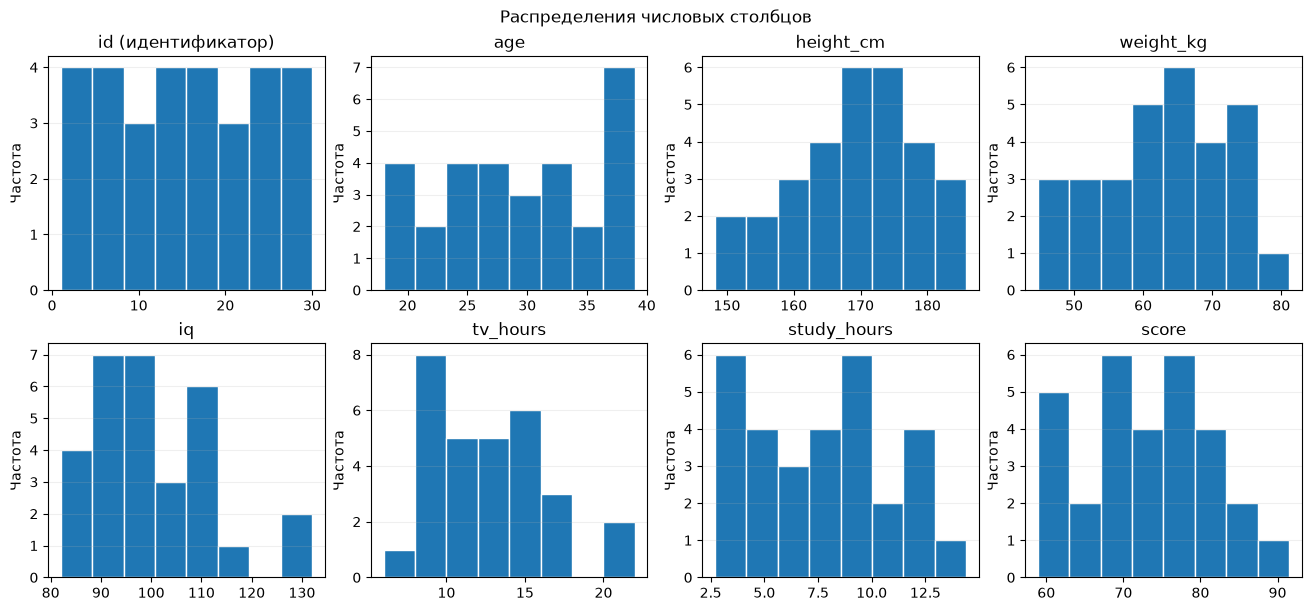

In [3]:
# Используем описательную статистику, гистограммы и правило 1,5 IQR.
print("Типы и пропуски по столбцам")
print(pd.DataFrame({"тип": df.dtypes.astype(str), "пропуски": df.isna().sum()}).to_string())
print(f"Дубли строк: {df.duplicated().sum()}")
print()
print("Описательная статистика по всем столбцам")
print(df.describe(include="all").T.round(3).to_string())

numeric = df.select_dtypes(include="number")
q1 = numeric.quantile(0.25)
q3 = numeric.quantile(0.75)
iqr = q3 - q1
outliers = (numeric.lt(q1 - 1.5 * iqr) | numeric.gt(q3 + 1.5 * iqr)).sum()
print()
print("Асимметрия и число наблюдений за границами 1,5 IQR")
print(pd.DataFrame({"асимметрия": numeric.skew(), "за границами": outliers}).round(3).to_string())

fig, axes = plt.subplots(2, 4, figsize=(13, 6.0), layout="constrained")
for ax, col in zip(axes.flat, numeric.columns):
    ax.hist(numeric[col], bins=8, color="tab:blue", edgecolor="white")
    ax.set_title("id (идентификатор)" if col == "id" else col)
    ax.set_ylabel("Частота")
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Распределения числовых столбцов")
plt.show()

**Вывод.** В 30 строках все столбцы числовые, пропусков и полных дублей нет, а id служит идентификатором. У iq и tv_hours заметен правый хвост, два значения tv_hours = 22 выходят за верхнюю границу по правилу 1,5 межквартильного размаха, а у остальных содержательных числовых признаков асимметрия невелика (|skew| < 0,3).

### Задание 2. Связь height_cm и weight_kg

- Постройте scatter plot по признакам `height_cm` и `weight_kg`.
- Посчитайте коэффициент Пирсона и p-value.
- Интерпретируйте силу, направление и значимость связи в выводе.

Пирсон: r = 0.9435, p-value = 5.79897e-15


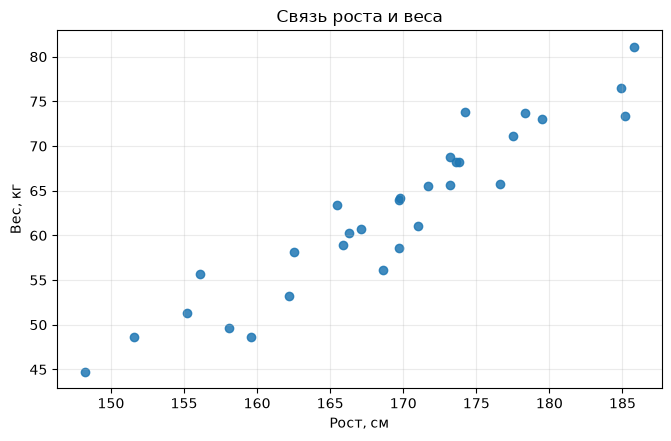

In [4]:
# Оцениваем линейную связь коэффициентом Пирсона и его двусторонним тестом.
height_weight = stats.pearsonr(df["height_cm"], df["weight_kg"])
print(f"Пирсон: r = {height_weight.statistic:.4f}, p-value = {height_weight.pvalue:.6g}")

fig, ax = plt.subplots(figsize=(6.6, 4.3), layout="constrained")
ax.scatter(df["height_cm"], df["weight_kg"], color="tab:blue", alpha=0.85)
ax.set(xlabel="Рост, см", ylabel="Вес, кг", title="Связь роста и веса")
ax.grid(alpha=0.25)
plt.show()

**Вывод.** Рост и вес демонстрируют сильную положительную линейную связь (r = 0,9435). Связь статистически значима на уровне 5% (p ≈ 5,80 × 10⁻¹⁵).

### Задание 3. Связь tv_hours и iq

- Посчитайте ранговый коэффициент Спирмена между `tv_hours` и `iq` и p-value.
- Оцените, есть ли монотонная связь в выводе.

In [5]:
# Оцениваем монотонную связь по рангам с помощью коэффициента Спирмена.
tv_iq = stats.spearmanr(df["tv_hours"], df["iq"])
print(f"Спирмен: r_s = {tv_iq.statistic:.4f}, p-value = {tv_iq.pvalue:.6f}")

Спирмен: r_s = -0.2108, p-value = 0.263541


**Вывод.** Выборочная монотонная связь слабая и отрицательная (rₛ = −0,2108). При p = 0,2635 выборка не даёт оснований утверждать, что такая связь есть в генеральной совокупности.

### Задание 4. Простая линейная регрессия weight_kg ~ height_cm

- Постройте регрессию, найдите intercept и slope, 95% доверительный интервал для наклона.
- Интерпретируйте результат в выводе.

In [6]:
# Оцениваем модель методом наименьших квадратов (МНК) со свободным членом.
weight_design = sm.add_constant(df[["height_cm"]], has_constant="add")
weight_model = sm.OLS(df["weight_kg"], weight_design).fit()
slope_low, slope_high = weight_model.conf_int(alpha=0.05).loc["height_cm"]
print(f"Свободный член = {weight_model.params['const']:.4f} кг")
print(f"Наклон = {weight_model.params['height_cm']:.4f} кг/см")
print(f"95%-й ДИ для наклона = [{slope_low:.4f}; {slope_high:.4f}] кг/см")

Свободный член = -90.4962 кг
Наклон = 0.9059 кг/см
95%-й ДИ для наклона = [0.7827; 1.0290] кг/см


**Вывод.** При увеличении роста на 1 см модель предсказывает увеличение среднего веса примерно на 0,906 кг. 95%-й доверительный интервал для наклона составляет от 0,783 до 1,029 кг/см и целиком лежит выше нуля.

### Задание 5. Прогноз и предсказательный интервал

- Для `height_cm = 175` вычислите точечный прогноз веса и 95% предсказательный интервал для нового наблюдения.

In [7]:
# Строим интервал для нового наблюдения по модели из задания 4.
new_height = pd.DataFrame({"const": [1.0], "height_cm": [175.0]})
prediction = weight_model.get_prediction(new_height[weight_design.columns]).summary_frame(alpha=0.05).iloc[0]
print(f"Прогноз веса при росте 175 см: {prediction['mean']:.2f} кг")
print(f"95%-й предсказательный интервал: "
      f"[{prediction['obs_ci_lower']:.2f}; {prediction['obs_ci_upper']:.2f}] кг")

Прогноз веса при росте 175 см: 68.03 кг
95%-й предсказательный интервал: [61.53; 74.53] кг


**Вывод.** При росте 175 см точечный прогноз составляет 68,03 кг. 95%-й предсказательный интервал от 61,53 до 74,53 кг относится к весу отдельного нового наблюдения.

### Задание 6. Множественная регрессия

- Постройте модель score `~ study_hours + iq + tv_hours + age`.
- Выведите R^2 и оцените значимость предикторов по p-value.
- Дополнительно проверьте мультиколлинеарность через VIF.
- Запшите наблюдения в выводе.

In [8]:
# Оцениваем множественную модель МНК и считаем VIF при наличии свободного члена.
predictors = ["study_hours", "iq", "tv_hours", "age"]
score_design = sm.add_constant(df[predictors], has_constant="add")
score_model = sm.OLS(df["score"], score_design).fit()
coefficient_table = pd.DataFrame({
    "коэффициент": score_model.params,
    "p-value": score_model.pvalues,
})
print(coefficient_table.to_string(float_format=lambda value: f"{value:.6g}"))
print(f"R² = {score_model.rsquared:.4f}")

vif = pd.Series({
    name: variance_inflation_factor(score_design.to_numpy(), score_design.columns.get_loc(name))
    for name in predictors
}, name="VIF")
print("VIF предикторов")
print(vif.round(3).to_string())

             коэффициент     p-value
const            45.6584 4.97988e-07
study_hours      2.09783 6.05641e-11
iq               0.14793   0.0100592
tv_hours       -0.144698    0.370176
age           -0.0465317    0.614106
R² = 0.8741
VIF предикторов
study_hours    1.174
iq             1.208
tv_hours       1.076
age            1.078


**Вывод.** Модель объясняет 87,41% выборочной вариации `score` при VIF от 1,08 до 1,21 (слабая мультиколлинеарность), а при фиксированных остальных признаках на уровне 5% значимы положительные коэффициенты `study_hours` ($p = 6{,}06 \cdot 10^{-11}$) и `iq` ($p = 0{,}0101$), тогда как для `tv_hours` ($p = 0{,}3702$) и `age` ($p = 0{,}6141$) значимость не подтверждена.

Исходные коэффициенты выражены в баллах `score` за единицу своего признака (например, за час занятий, балл IQ или год возраста) и зависят от масштаба, поэтому для сравнения эффектов нужна общая шкала, например изменение каждого признака на одно стандартное отклонение.

### Задание 7. Ошибка модели

- Оцените типичную ошибку предсказаний модели из задания 6: вычислите RMSE (корень из средней квадратичной ошибки) на всей выборке и сравните её с разбросом целевой переменной (стандартным отклонением score).
- Насколько модель уменьшает типичную ошибку?

In [9]:
# Сравниваем RMSE на всех 30 строках с разбросом score и с прогнозом по среднему.
score = df["score"]
rmse = np.sqrt(np.mean(np.square(score_model.resid)))
score_sd = score.std(ddof=1)
mean_model_rmse = np.sqrt(np.mean(np.square(score - score.mean())))
rmse_reduction = 1 - rmse / mean_model_rmse
print(f"RMSE модели: {rmse:.4f} балла")
print(f"Выборочное стандартное отклонение score: {score_sd:.4f} балла")
print(f"RMSE прогноза по среднему: {mean_model_rmse:.4f} балла")
print(f"Снижение RMSE относительно прогноза по среднему: {rmse_reduction:.1%}")

RMSE модели: 2.8797 балла
Выборочное стандартное отклонение score: 8.2537 балла
RMSE прогноза по среднему: 8.1150 балла
Снижение RMSE относительно прогноза по среднему: 64.5%


**Вывод.** На всех 30 наблюдениях RMSE равна 2,88 балла при выборочном стандартном отклонении score 8,25 балла. По сравнению с прогнозом по среднему RMSE на той же выборке снизилась на 64,5%.

### Задание 8. Градиентный спуск

- Реализуйте градиентный спуск для простой регрессии score `~ study_hours` и сравните коэффициенты со `statsmodels`.
- Ответьте на вопрос: возможно ли получить метрику алгоритмом градиентного спуска лучше, чем у МНК?

In [10]:
# Минимизируем MSE пакетным градиентным спуском по двум параметрам.
x = df["study_hours"].to_numpy(dtype=float)
y = df["score"].to_numpy(dtype=float)
x_mean, x_sd = x.mean(), x.std(ddof=0)
x_scaled = (x - x_mean) / x_sd
design = np.column_stack((np.ones(x.size), x_scaled))
learning_rate, iterations = 0.1, 1000
theta = np.zeros(2)
for _ in range(iterations):
    errors = design @ theta - y
    theta -= learning_rate * (2 / y.size) * (design.T @ errors)

gd_slope = theta[1] / x_sd
gd_intercept = theta[0] - gd_slope * x_mean
gd_mse = np.mean(np.square(gd_intercept + gd_slope * x - y))
ols_study = sm.OLS(y, sm.add_constant(x, has_constant="add")).fit()
ols_mse = np.mean(np.square(ols_study.resid))

print(f"Шаг = {learning_rate}, итераций = {iterations}")
print(f"Градиентный спуск: b0 = {gd_intercept:.6f}, b1 = {gd_slope:.6f}, MSE = {gd_mse:.6f}")
print(f"МНК: b0 = {ols_study.params[0]:.6f}, b1 = {ols_study.params[1]:.6f}, MSE = {ols_mse:.6f}")
print(f"Максимальное расхождение коэффициентов: "
      f"{np.max(np.abs(np.array([gd_intercept, gd_slope]) - ols_study.params)):.3g}")

Шаг = 0.1, итераций = 1000
Градиентный спуск: b0 = 56.034028, b1 = 2.273033, MSE = 12.068919
МНК: b0 = 56.034028, b1 = 2.273033, MSE = 12.068919
Максимальное расхождение коэффициентов: 1.42e-14


**Вывод.** Градиентный спуск сошёлся к тем же коэффициентам и обучающей MSE 12,069, что и МНК. Уменьшить эту MSE градиентным спуском при тех же данных и модели нельзя, поскольку МНК уже достигает её минимума.

### Задание 9. Бутстрэп-интервал для корреляции

- Постройте бутстрэп-оценку 95% доверительного интервала для коэффициента Пирсона между `height_cm` и `weight_kg` (1000 бутстрэп-итераций, перцентильный метод).

In [11]:
# Пересэмплируем пары «рост–вес» целыми строками, сохраняя связь внутри пары.
height = df["height_cm"].to_numpy()
weight = df["weight_kg"].to_numpy()
replications = 1000
row_indices = np.random.randint(0, len(df), size=(replications, len(df)))
correlations = np.array([
    np.corrcoef(height[indices], weight[indices])[0, 1]
    for indices in row_indices
])
bootstrap_low, bootstrap_high = np.percentile(correlations, [2.5, 97.5])
print(f"Бутстрэп-репликаций: {replications}")
print(f"Выборочный r = {height_weight.statistic:.4f}")
print(f"95%-й перцентильный ДИ: [{bootstrap_low:.4f}; {bootstrap_high:.4f}]")

Бутстрэп-репликаций: 1000
Выборочный r = 0.9435
95%-й перцентильный ДИ: [0.9021; 0.9705]


**Вывод.** 95%-й перцентильный интервал для корреляции Пирсона составляет [0,9021; 0,9705]. При 1000 повторных выборках пар «рост–вес» он целиком лежит в области сильной положительной связи.

### Задание 10. Диагностика остатков

Для модели из задания 6 проведите диагностику остатков:
- постройте график остатков против предсказанных значений,
- QQ-plot остатков и гистограмму остатков.

Сделайте вывод о выполнении предпосылок регрессии.

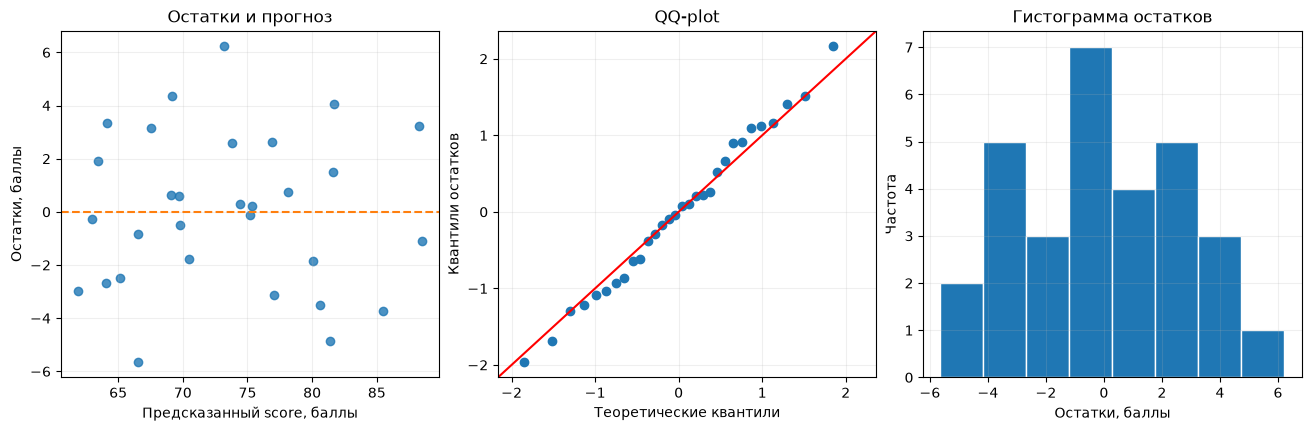

Диагностика нормальности, Шапиро–Уилк: p-value = 0.9616
Диагностика постоянства дисперсии, Бройш–Паган: p-value = 0.9886


In [12]:
# Проверяем форму остатков и постоянство их разброса вокруг линии модели.
from statsmodels.stats.diagnostic import het_breuschpagan

residuals = score_model.resid
fitted = score_model.fittedvalues
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), layout="constrained")
axes[0].scatter(fitted, residuals, color="tab:blue", alpha=0.8)
axes[0].axhline(0, color="tab:orange", linestyle="--")
axes[0].set(xlabel="Предсказанный score, баллы", ylabel="Остатки, баллы", title="Остатки и прогноз")
sm.qqplot(residuals, line="45", fit=True, ax=axes[1])
axes[1].set(xlabel="Теоретические квантили", ylabel="Квантили остатков", title="QQ-plot")
axes[2].hist(residuals, bins=8, color="tab:blue", edgecolor="white")
axes[2].set(xlabel="Остатки, баллы", ylabel="Частота", title="Гистограмма остатков")
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

normality = stats.shapiro(residuals)
_, bp_p, _, _ = het_breuschpagan(residuals, score_design)
print(f"Диагностика нормальности, Шапиро–Уилк: p-value = {normality.pvalue:.4f}")
print(f"Диагностика постоянства дисперсии, Бройш–Паган: p-value = {bp_p:.4f}")

**Вывод.** На графике остатков нет выраженной воронки или кривизны, а QQ-plot и гистограмма совместимы с приближённой нормальностью. Диагностические тесты также не выявили этих нарушений при уровне 5%, а независимость наблюдений зависит от способа сбора данных.